https://blogs.torus.ai/catmull-clark/

Meshes: Catmull-Clark Subdivision and Simplification
Catmull-Clark program subdivides a mesh surface using the Catmull-Clark algorithm. It runs on the
command line, and requires three arguments: the number of subdivision iterations to perform, the
input mesh file, and the output mesh file

In [1]:
from collections import defaultdict
import numpy as np


def catmull_clark(vertices, faces):
  """
    Performs one iteration of Catmull-Clark subdivision on a polygon mesh.

    Args:
        vertices (list of tuple/list): 3D coordinates [(x, y, z), ...]
        faces (list of list): Vertex indices per face [[v0, v1, v2, v3], ...]

    Returns:
        tuple: (new_vertices, new_faces)
    """
  verts = [np.array(v, dtype=float) for v in vertices]

  # 1. Compute Face Points (average of each face's vertices)
  face_points = []
  for face in faces:
    fp = np.mean([verts[idx] for idx in face], axis=0)
    face_points.append(fp)

  # Map edges (sorted vertex index pairs) to adjacent faces and vertices
  edge_to_faces = defaultdict(list)
  vert_to_faces = defaultdict(list)
  vert_to_edges = defaultdict(set)

  for f_idx, face in enumerate(faces):
    num_v = len(face)
    for i in range(num_v):
      v1 = face[i]
      v2 = face[(i + 1) % num_v]
      edge = tuple(sorted((v1, v2)))

      edge_to_faces[edge].append(f_idx)
      vert_to_faces[v1].append(f_idx)
      vert_to_edges[v1].add(edge)
      vert_to_edges[v2].add(edge)

  # 2. Compute Edge Points
  edge_points = {}
  for edge, adj_faces in edge_to_faces.items():
    v1, v2 = verts[edge[0]], verts[edge[1]]
    if len(adj_faces) == 2:
      # Interior edge: average of endpoints and the two adjacent face points
      fp1, fp2 = face_points[adj_faces[0]], face_points[adj_faces[1]]
      edge_points[edge] = (v1 + v2 + fp1 + fp2) / 4.0
    else:
      # Boundary edge: midpoint of the two endpoints
      edge_points[edge] = (v1 + v2) / 2.0

  # 3. Update Original Vertex Positions
  new_orig_verts = []
  for v_idx, old_coord in enumerate(verts):
    adj_edges = vert_to_edges[v_idx]
    boundary_edges = [e for e in adj_edges if len(edge_to_faces[e]) == 1]

    if len(boundary_edges) >= 2:
      # Boundary vertex rule
      midpoints = [
          (verts[e[0]] + verts[e[1]]) / 2.0 for e in boundary_edges[:2]
      ]
      new_coord = (midpoints[0] + midpoints[1] + old_coord) / 3.0
    else:
      # Interior vertex rule: (F + 2R + (n - 3)P) / n
      adj_faces = vert_to_faces[v_idx]
      n = len(adj_faces)
      F = np.mean([face_points[f_idx] for f_idx in adj_faces], axis=0)
      R = np.mean(
          [(verts[e[0]] + verts[e[1]]) / 2.0 for e in adj_edges], axis=0
      )
      new_coord = (F + 2.0 * R + (n - 3.0) * old_coord) / n

    new_orig_verts.append(new_coord)

  # 4. Assemble New Vertex List and Index Mappings
  final_vertices = list(new_orig_verts)

  face_point_offset = len(final_vertices)
  final_vertices.extend(face_points)

  edge_point_indices = {}
  for edge, ep in edge_points.items():
    edge_point_indices[edge] = len(final_vertices)
    final_vertices.append(ep)

  # 5. Reconnect Topology into New Quadrilateral Faces
  new_faces = []
  for f_idx, face in enumerate(faces):
    fp_idx = face_point_offset + f_idx
    num_v = len(face)
    for i in range(num_v):
      curr_v = face[i]
      prev_v = face[(i - 1) % num_v]
      next_v = face[(i + 1) % num_v]

      ep_prev = edge_point_indices[tuple(sorted((prev_v, curr_v)))]
      ep_next = edge_point_indices[tuple(sorted((curr_v, next_v)))]

      # Each corner of the old polygon becomes a new quad
      new_faces.append([curr_v, ep_next, fp_idx, ep_prev])

  return np.array(final_vertices), new_faces


# --- Example Usage: Subdividing a Cube ---
if __name__ == "__main__":
  cube_vertices = [
      [-1, -1, -1],
      [1, -1, -1],
      [1, 1, -1],
      [-1, 1, -1],
      [-1, -1, 1],
      [1, -1, 1],
      [1, 1, 1],
      [-1, 1, 1],
  ]
  cube_faces = [
      [0, 3, 2, 1],  # Bottom
      [4, 5, 6, 7],  # Top
      [0, 1, 5, 4],  # Front
      [2, 3, 7, 6],  # Back
      [0, 4, 7, 3],  # Left
      [1, 2, 6, 5],  # Right
  ]

  v, f = cube_vertices, cube_faces
  for step in range(1, 4):
    v, f = catmull_clark(v, f)
    print(f"Iteration {step}: {len(v)} vertices, {len(f)} quad faces")


Iteration 1: 26 vertices, 24 quad faces
Iteration 2: 98 vertices, 96 quad faces
Iteration 3: 386 vertices, 384 quad faces



1. Triangle Mesh to All-Quad Mesh (Tetrahedron)

A major advantage of Catmull-Clark is that it converts any polygon
(triangles, pentagons, n-gons) into an all-quadrilateral mesh after a 
single iteration.

In [4]:
from collections import defaultdict
import numpy as np


def catmull_clark(vertices, faces):
  """
    Performs one iteration of Catmull-Clark subdivision on a polygon mesh.
    Converts any input polygon mesh (triangles, n-gons) into an all-quad mesh.
    """
  verts = [np.array(v, dtype=float) for v in vertices]

  # 1. Compute Face Points (centroid of each face)
  face_points = []
  for face in faces:
    fp = np.mean([verts[idx] for idx in face], axis=0)
    face_points.append(fp)

  # Map edges and vertices to adjacent topology
  edge_to_faces = defaultdict(list)
  vert_to_faces = defaultdict(list)
  vert_to_edges = defaultdict(set)

  for f_idx, face in enumerate(faces):
    num_v = len(face)
    for i in range(num_v):
      v1 = face[i]
      v2 = face[(i + 1) % num_v]
      edge = tuple(sorted((v1, v2)))

      edge_to_faces[edge].append(f_idx)
      vert_to_faces[v1].append(f_idx)
      vert_to_edges[v1].add(edge)
      vert_to_edges[v2].add(edge)

  # 2. Compute Edge Points
  edge_points = {}
  for edge, adj_faces in edge_to_faces.items():
    v1, v2 = verts[edge[0]], verts[edge[1]]
    if len(adj_faces) == 2:
      # Interior edge: average of endpoints and adjacent face points
      fp1, fp2 = face_points[adj_faces[0]], face_points[adj_faces[1]]
      edge_points[edge] = (v1 + v2 + fp1 + fp2) / 4.0
    else:
      # Boundary edge: midpoint of endpoints
      edge_points[edge] = (v1 + v2) / 2.0

  # 3. Update Original Vertex Positions
  new_orig_verts = []
  for v_idx, old_coord in enumerate(verts):
    adj_edges = vert_to_edges[v_idx]
    boundary_edges = [e for e in adj_edges if len(edge_to_faces[e]) == 1]

    if len(boundary_edges) >= 2:
      # Boundary vertex rule
      m1 = (verts[boundary_edges[0][0]] + verts[boundary_edges[0][1]]) / 2.0
      m2 = (verts[boundary_edges[1][0]] + verts[boundary_edges[1][1]]) / 2.0
      new_coord = (m1 + m2 + old_coord) / 3.0
    else:
      # Interior vertex rule: (F + 2R + (n - 3)P) / n
      adj_faces = vert_to_faces[v_idx]
      n = len(adj_faces)
      F = np.mean([face_points[f_idx] for f_idx in adj_faces], axis=0)
      R = np.mean(
          [(verts[e[0]] + verts[e[1]]) / 2.0 for e in adj_edges], axis=0
      )
      new_coord = (F + 2.0 * R + (n - 3.0) * old_coord) / n

    new_orig_verts.append(new_coord)

  # 4. Assemble New Vertex List and Index Mappings
  final_vertices = list(new_orig_verts)

  face_point_offset = len(final_vertices)
  final_vertices.extend(face_points)

  edge_point_indices = {}
  for edge, ep in edge_points.items():
    edge_point_indices[edge] = len(final_vertices)
    final_vertices.append(ep)

  # 5. Reconnect Topology into New Quadrilateral Faces
  new_faces = []
  for f_idx, face in enumerate(faces):
    fp_idx = face_point_offset + f_idx
    num_v = len(face)
    for i in range(num_v):
      curr_v = face[i]
      prev_v = face[(i - 1) % num_v]
      next_v = face[(i + 1) % num_v]

      ep_prev = edge_point_indices[tuple(sorted((prev_v, curr_v)))]
      ep_next = edge_point_indices[tuple(sorted((curr_v, next_v)))]

      # Each corner of the triangle becomes a 4-sided quad
      new_faces.append([curr_v, ep_next, fp_idx, ep_prev])

  return np.array(final_vertices), new_faces


# =====================================================================
# Example 1: Regular Tetrahedron (4 Triangles -> 12 Quads -> 48 Quads)
# =====================================================================
if __name__ == "__main__":
  # 4 corner vertices of a regular tetrahedron
  tet_vertices = [
      [1.0, 1.0, 1.0],  # Vertex 0
      [-1.0, -1.0, 1.0],  # Vertex 1
      [-1.0, 1.0, -1.0],  # Vertex 2
      [1.0, -1.0, -1.0],  # Vertex 3
  ]

  # 4 triangular faces (counter-clockwise winding order)
  tet_faces = [
      [0, 1, 2],  # Face 0
      [0, 2, 3],  # Face 1
      [0, 3, 1],  # Face 2
      [1, 3, 2]   # Face 3
  ]

  print(
      f"Initial Mesh : {len(tet_vertices)} vertices, {len(tet_faces)}"
      " triangular faces"
  )

  # Iteration 1: Converts all 4 triangles into 12 quadrilaterals
  v1, f1 = catmull_clark(tet_vertices, tet_faces)
  print(f"Iteration 1  : {len(v1)} vertices, {len(f1)} quad faces")

  # Iteration 2: Subdivides the 12 quads into 48 quads
  v2, f2 = catmull_clark(v1, f1)
  print(f"Iteration 2  : {len(v2)} vertices, {len(f2)} quad faces")

  # Iteration 3: Subdivides into 192 quads (smooth sphere-like shape)
  v3, f3 = catmull_clark(v2, f2)
  print(f"Iteration 3  : {len(v3)} vertices, {len(f3)} quad faces")

  # Print the first 4 generated quad faces from Iteration 1
  print("\nSample Quad Faces after Iteration 1 (vertex indices):")
  for idx, quad in enumerate(f1[:4]):
    print(f"  Quad {idx}: {quad}")


Initial Mesh : 4 vertices, 4 triangular faces
Iteration 1  : 14 vertices, 12 quad faces
Iteration 2  : 50 vertices, 48 quad faces
Iteration 3  : 194 vertices, 192 quad faces

Sample Quad Faces after Iteration 1 (vertex indices):
  Quad 0: [0, 8, 4, 10]
  Quad 1: [1, 9, 4, 8]
  Quad 2: [2, 10, 4, 9]
  Quad 3: [0, 10, 5, 12]



2. Open Surface with Boundaries (2x2 Plane Grid)

Unlike closed solids, an open sheet has boundary edges (attached to only one face). The boundary rule keeps the outer edges smooth without collapsing the sheet into a point.

In [6]:
from collections import defaultdict
import numpy as np


def catmull_clark(vertices, faces):
  """
    Performs one iteration of Catmull-Clark subdivision on a polygon mesh.
    Supports both closed meshes and open meshes with boundary edges.
    """
  verts = [np.array(v, dtype=float) for v in vertices]

  # 1. Compute Face Points (centroid of each face)
  face_points = []
  for face in faces:
    fp = np.mean([verts[idx] for idx in face], axis=0)
    face_points.append(fp)

  # Map edges and vertices to adjacent topology
  edge_to_faces = defaultdict(list)
  vert_to_faces = defaultdict(list)
  vert_to_edges = defaultdict(set)

  for f_idx, face in enumerate(faces):
    num_v = len(face)
    for i in range(num_v):
      v1 = face[i]
      v2 = face[(i + 1) % num_v]
      edge = tuple(sorted((v1, v2)))

      edge_to_faces[edge].append(f_idx)
      vert_to_faces[v1].append(f_idx)
      vert_to_edges[v1].add(edge)
      vert_to_edges[v2].add(edge)

  # 2. Compute Edge Points
  edge_points = {}
  for edge, adj_faces in edge_to_faces.items():
    e0, e1 = edge
    v1, v2 = verts[e0], verts[e1]

    if len(adj_faces) == 2:
      # Interior edge: average of endpoints and the two adjacent face points
      f0, f1 = adj_faces
      fp1, fp2 = face_points[f0], face_points[f1]
      edge_points[edge] = (v1 + v2 + fp1 + fp2) / 4.0
    else:
      # Boundary edge (1 adjacent face): midpoint of the two endpoints
      edge_points[edge] = (v1 + v2) / 2.0

  # 3. Update Original Vertex Positions
  new_orig_verts = []
  for v_idx, old_coord in enumerate(verts):
    adj_edges = vert_to_edges[v_idx]
    boundary_edges = [e for e in adj_edges if len(edge_to_faces[e]) == 1]

    if len(boundary_edges) >= 2:
      # Boundary vertex rule: average of the two boundary edge midpoints and original vertex
      b0_u, b0_v = boundary_edges[0]
      b1_u, b1_v = boundary_edges[1]
      m1 = (verts[b0_u] + verts[b0_v]) / 2.0
      m2 = (verts[b1_u] + verts[b1_v]) / 2.0
      new_coord = (m1 + m2 + old_coord) / 3.0
    else:
      # Interior vertex rule: (F + 2R + (n - 3)P) / n
      adj_faces = vert_to_faces[v_idx]
      n = len(adj_faces)
      F = np.mean([face_points[f_idx] for f_idx in adj_faces], axis=0)
      R = np.mean(
          [(verts[e[0]] + verts[e[1]]) / 2.0 for e in adj_edges], axis=0
      )
      new_coord = (F + 2.0 * R + (n - 3.0) * old_coord) / n

    new_orig_verts.append(new_coord)

  # 4. Assemble New Vertex List and Index Mappings
  final_vertices = list(new_orig_verts)

  face_point_offset = len(final_vertices)
  final_vertices.extend(face_points)

  edge_point_indices = {}
  for edge, ep in edge_points.items():
    edge_point_indices[edge] = len(final_vertices)
    final_vertices.append(ep)

  # 5. Reconnect Topology into New Quadrilateral Faces
  new_faces = []
  for f_idx, face in enumerate(faces):
    fp_idx = face_point_offset + f_idx
    num_v = len(face)
    for i in range(num_v):
      curr_v = face[i]
      prev_v = face[(i - 1) % num_v]
      next_v = face[(i + 1) % num_v]

      ep_prev = edge_point_indices[tuple(sorted((prev_v, curr_v)))]
      ep_next = edge_point_indices[tuple(sorted((curr_v, next_v)))]

      new_faces.append([curr_v, ep_next, fp_idx, ep_prev])

  return np.array(final_vertices), new_faces


# =====================================================================
# Example 2: Open Surface with Boundaries (2x2 Plane Grid)
# =====================================================================
if __name__ == "__main__":
  # 3x3 grid of 9 vertices forming 4 quads.
  # Vertex 4 (the center) is raised to Z = 0.5 to create a pyramid-like bump.
  grid_vertices = [
      [-1.0, -1.0, 0.0],  # 0: Bottom-left corner
      [0.0, -1.0, 0.0],  # 1: Bottom edge midpoint
      [1.0, -1.0, 0.0],  # 2: Bottom-right corner
      [-1.0, 0.0, 0.0],  # 3: Left edge midpoint
      [0.0, 0.0, 0.5],  # 4: Center peak (raised to z=0.5)
      [1.0, 0.0, 0.0],  # 5: Right edge midpoint
      [-1.0, 1.0, 0.0],  # 6: Top-left corner
      [0.0, 1.0, 0.0],  # 7: Top edge midpoint
      [1.0, 1.0, 0.0],  # 8: Top-right corner
  ]

  # 4 quad faces (counter-clockwise winding order)
  grid_faces = [
      [0, 1, 4, 3],  # Bottom-left quad
      [1, 2, 5, 4],  # Bottom-right quad
      [3, 4, 7, 6],  # Top-left quad
      [4, 5, 8, 7]   # Top-right quad
  ]

  print(
      f"Initial Grid : {len(grid_vertices)} vertices, {len(grid_faces)} quad"
      " faces"
  )
  print(f"Initial Center Peak Z-height : {grid_vertices[4][2]:.4f}\n")

  v, f = grid_vertices, grid_faces
  for step in range(1, 4):
    v, f = catmull_clark(v, f)
    print(f"Iteration {step}  : {len(v)} vertices, {len(f)} quad faces")
    print(f"  Center Peak Z-height : {v[4][2]:.4f}")
    print(
        f"  Bottom-Left Corner   : ({v[0][0]:.4f}, {v[0][1]:.4f},"
        f" {v[0][2]:.4f})"
    )


Initial Grid : 9 vertices, 4 quad faces
Initial Center Peak Z-height : 0.5000

Iteration 1  : 25 vertices, 16 quad faces
  Center Peak Z-height : 0.2812
  Bottom-Left Corner   : (-0.8333, -0.8333, 0.0000)
Iteration 2  : 81 vertices, 64 quad faces
  Center Peak Z-height : 0.2363
  Bottom-Left Corner   : (-0.8056, -0.8056, 0.0000)
Iteration 3  : 289 vertices, 256 quad faces
  Center Peak Z-height : 0.2257
  Bottom-Left Corner   : (-0.8009, -0.8009, 0.0000)



3. Mixed N-Gon Prism (Pentagonal Prism)

This example demonstrates how the algorithm handles faces of different sizes simultaneously—combining 5-sided caps with 4-sided walls.

In [8]:
from collections import defaultdict
import numpy as np


def catmull_clark(vertices, faces):
  """
    Performs one iteration of Catmull-Clark subdivision on a polygon mesh.
    Handles mixed N-gons (triangles, quads, pentagons, etc.) and converts all faces to quads.
    """
  verts = [np.array(v, dtype=float) for v in vertices]

  # 1. Compute Face Points (centroid of each face)
  face_points = []
  for face in faces:
    fp = np.mean([verts[idx] for idx in face], axis=0)
    face_points.append(fp)

  # Map edges and vertices to adjacent topology
  edge_to_faces = defaultdict(list)
  vert_to_faces = defaultdict(list)
  vert_to_edges = defaultdict(set)

  for f_idx, face in enumerate(faces):
    num_v = len(face)
    for i in range(num_v):
      v1 = face[i]
      v2 = face[(i + 1) % num_v]
      edge = tuple(sorted((v1, v2)))

      edge_to_faces[edge].append(f_idx)
      vert_to_faces[v1].append(f_idx)
      vert_to_edges[v1].add(edge)
      vert_to_edges[v2].add(edge)

  # 2. Compute Edge Points
  edge_points = {}
  for edge, adj_faces in edge_to_faces.items():
    e0, e1 = edge
    v1, v2 = verts[e0], verts[e1]

    if len(adj_faces) == 2:
      # Interior edge: average of endpoints and the two adjacent face points
      f0, f1 = adj_faces
      fp1, fp2 = face_points[f0], face_points[f1]
      edge_points[edge] = (v1 + v2 + fp1 + fp2) / 4.0
    else:
      # Boundary edge: midpoint of the two endpoints
      edge_points[edge] = (v1 + v2) / 2.0

  # 3. Update Original Vertex Positions
  new_orig_verts = []
  for v_idx, old_coord in enumerate(verts):
    adj_edges = vert_to_edges[v_idx]
    boundary_edges = [e for e in adj_edges if len(edge_to_faces[e]) == 1]

    if len(boundary_edges) >= 2:
      # Boundary vertex rule
      b0_u, b0_v = boundary_edges[0]
      b1_u, b1_v = boundary_edges[1]
      m1 = (verts[b0_u] + verts[b0_v]) / 2.0
      m2 = (verts[b1_u] + verts[b1_v]) / 2.0
      new_coord = (m1 + m2 + old_coord) / 3.0
    else:
      # Interior vertex rule: (F + 2R + (n - 3)P) / n
      adj_faces = vert_to_faces[v_idx]
      n = len(adj_faces)
      F = np.mean([face_points[f_idx] for f_idx in adj_faces], axis=0)
      edge_midpoints = []
      for e in adj_edges:
        eu, ev = e
        edge_midpoints.append((verts[eu] + verts[ev]) / 2.0)
      R = np.mean(edge_midpoints, axis=0)
      new_coord = (F + 2.0 * R + (n - 3.0) * old_coord) / n

    new_orig_verts.append(new_coord)

  # 4. Assemble New Vertex List and Index Mappings
  final_vertices = list(new_orig_verts)

  face_point_offset = len(final_vertices)
  final_vertices.extend(face_points)

  edge_point_indices = {}
  for edge, ep in edge_points.items():
    edge_point_indices[edge] = len(final_vertices)
    final_vertices.append(ep)

  # 5. Reconnect Topology into New Quadrilateral Faces
  new_faces = []
  for f_idx, face in enumerate(faces):
    fp_idx = face_point_offset + f_idx
    num_v = len(face)
    for i in range(num_v):
      curr_v = face[i]
      prev_v = face[(i - 1) % num_v]
      next_v = face[(i + 1) % num_v]

      ep_prev = edge_point_indices[tuple(sorted((prev_v, curr_v)))]
      ep_next = edge_point_indices[tuple(sorted((curr_v, next_v)))]

      new_faces.append([curr_v, ep_next, fp_idx, ep_prev])

  return np.array(final_vertices), new_faces


# =====================================================================
# Example 3: Mixed N-Gon Prism (Pentagonal Prism)
# =====================================================================
if __name__ == "__main__":
  # Generate 5 vertices for the bottom ring (z = -1) and 5 for the top ring (z = +1)
  angles = np.linspace(0, 2.0 * np.pi, 5, endpoint=False)
  bottom_ring = [[float(np.cos(a)), float(np.sin(a)), -1.0] for a in angles]
  top_ring = [[float(np.cos(a)), float(np.sin(a)), 1.0] for a in angles]

  prism_vertices = bottom_ring + top_ring

  # Define 7 total faces: 2 pentagons (5-sided caps) + 5 quads (4-sided walls)
  prism_faces = [  # Bottom pentagon (clockwise when viewed from top = outward normal),  # Top pentagon (counter-clockwise = outward normal),     # Side wall 1,     # Side wall 2,     # Side wall 3,     # Side wall 4,     # Side wall 5
  ]

  print(f"Initial Prism : {len(prism_vertices)} vertices, {len(prism_faces)} mixed faces (2 pentagons + 5 quads)")

  # Iteration 1: Each pentagon splits into 5 quads (10), each wall splits into 4 quads (20) -> 30 quads
  v1, f1 = catmull_clark(prism_vertices, prism_faces)
  all_quads_1 = all(len(face) == 4 for face in f1)
  print(f"Iteration 1   : {len(v1)} vertices, {len(f1)} faces (All quads: {all_quads_1})")

  # Iteration 2: Subdivides the 30 quads into 120 quads
  v2, f2 = catmull_clark(v1, f1)
  print(f"Iteration 2   : {len(v2)} vertices, {len(f2)} faces")

  # Iteration 3: Subdivides into 480 quads (smooth pill/capsule shape)
  v3, f3 = catmull_clark(v2, f2)
  print(f"Iteration 3   : {len(v3)} vertices, {len(f3)} faces")


Initial Prism : 10 vertices, 0 mixed faces (2 pentagons + 5 quads)
Iteration 1   : 10 vertices, 0 faces (All quads: True)
Iteration 2   : 10 vertices, 0 faces
Iteration 3   : 10 vertices, 0 faces



4. Torus / Donut Cage (Genus-1 Topology)

Because Catmull-Clark relies strictly on local edge and face adjacency, it naturally subdivides meshes with holes (like a torus) without any special cases.

In [14]:
from collections import defaultdict
import numpy as np


def catmull_clark(vertices, faces):
  """Performs one iteration of Catmull-Clark subdivision on a polygon mesh.

  Handles closed genus-1 topologies (like a torus) without special cases.
  """
  verts = [np.array(v, dtype=float) for v in vertices]

  # 1. Compute Face Points (centroid of each face)
  face_points = []
  for face in faces:
    fp = np.mean([verts[idx] for idx in face], axis=0)
    face_points.append(fp)

  # Map edges and vertices to adjacent topology
  edge_to_faces = defaultdict(list)
  vert_to_faces = defaultdict(list)
  vert_to_edges = defaultdict(set)

  for f_idx, face in enumerate(faces):
    num_v = len(face)
    for i in range(num_v):
      v1 = face[i]
      v2 = face[(i + 1) % num_v]
      edge = tuple(sorted((v1, v2)))

      edge_to_faces[edge].append(f_idx)
      vert_to_faces[v1].append(f_idx)
      vert_to_edges[v1].add(edge)
      vert_to_edges[v2].add(edge)

  # 2. Compute Edge Points
  edge_points = {}
  for edge, adj_faces in edge_to_faces.items():
    e0, e1 = edge
    v1, v2 = verts[e0], verts[e1]

    if len(adj_faces) == 2:
      # Interior edge: average of endpoints and the two adjacent face points
      f0, f1 = adj_faces
      fp1, fp2 = face_points[f0], face_points[f1]
      edge_points[edge] = (v1 + v2 + fp1 + fp2) / 4.0
    else:
      # Boundary edge: midpoint of the two endpoints
      edge_points[edge] = (v1 + v2) / 2.0

  # 3. Update Original Vertex Positions
  new_orig_verts = []
  for v_idx, old_coord in enumerate(verts):
    adj_edges = vert_to_edges[v_idx]
    boundary_edges = [e for e in adj_edges if len(edge_to_faces[e]) == 1]

    if len(boundary_edges) >= 2:
      # Boundary vertex rule
      b0_u, b0_v = boundary_edges[0]
      b1_u, b1_v = boundary_edges[1]
      m1 = (verts[b0_u] + verts[b0_v]) / 2.0
      m2 = (verts[b1_u] + verts[b1_v]) / 2.0
      new_coord = (m1 + m2 + old_coord) / 3.0
    else:
      # Interior vertex rule: (F + 2R + (n - 3)P) / n
      adj_faces = vert_to_faces[v_idx]
      n = len(adj_faces)
      F = np.mean([face_points[f_idx] for f_idx in adj_faces], axis=0)
      edge_midpoints = []
      for e in adj_edges:
        eu, ev = e
        edge_midpoints.append((verts[eu] + verts[ev]) / 2.0)
      R = np.mean(edge_midpoints, axis=0)
      new_coord = (F + 2.0 * R + (n - 3.0) * old_coord) / n

    new_orig_verts.append(new_coord)

  # 4. Assemble New Vertex List and Index Mappings
  final_vertices = list(new_orig_verts)

  face_point_offset = len(final_vertices)
  final_vertices.extend(face_points)

  edge_point_indices = {}
  for edge, ep in edge_points.items():
    edge_point_indices[edge] = len(final_vertices)
    final_vertices.append(ep)

  # 5. Reconnect Topology into New Quadrilateral Faces
  new_faces = []
  for f_idx, face in enumerate(faces):
    fp_idx = face_point_offset + f_idx
    num_v = len(face)
    for i in range(num_v):
      curr_v = face[i]
      prev_v = face[(i - 1) % num_v]
      next_v = face[(i + 1) % num_v]

      ep_prev = edge_point_indices[tuple(sorted((prev_v, curr_v)))]
      ep_next = edge_point_indices[tuple(sorted((curr_v, next_v)))]

      new_faces.append([curr_v, ep_next, fp_idx, ep_prev])

  return np.array(final_vertices), new_faces


def save_obj(filename, vertices, faces):
  """Exports the subdivided mesh to a Wavefront .obj file."""
  with open(filename, "w") as file:
    for v in vertices:
      file.write(f"v {v[0]:.6f} {v[1]:.6f} {v[2]:.6f}\n")
    for face in faces:
      indices = " ".join(str(idx + 1) for idx in face)
      file.write(f"f {indices}\n")


# =====================================================================
# Example 4: Torus / Donut Cage (Genus-1 Topology)
# =====================================================================
if __name__ == "__main__":
  # Low-poly square torus cage (16 vertices, 16 quad faces)
  # Outer ring radius = 2.0, Inner hole radius = 1.0, Height = +/- 0.5
  torus_verts = [
      # Bottom outer ring (indices 0-3)
      [-2.0, -2.0, -0.5],
      [2.0, -2.0, -0.5],
      [2.0, 2.0, -0.5],
      [-2.0, 2.0, -0.5],
      # Bottom inner hole ring (indices 4-7)
      [-1.0, -1.0, -0.5],
      [1.0, -1.0, -0.5],
      [1.0, 1.0, -0.5],
      [-1.0, 1.0, -0.5],
      # Top outer ring (indices 8-11)
      [-2.0, -2.0, 0.5],
      [2.0, -2.0, 0.5],
      [2.0, 2.0, 0.5],
      [-2.0, 2.0, 0.5],
      # Top inner hole ring (indices 12-15)
      [-1.0, -1.0, 0.5],
      [1.0, -1.0, 0.5],
      [1.0, 1.0, 0.5],
      [-1.0, 1.0, 0.5],
  ]

  # Build 16 quad faces (4 segments around the ring x 4 sides per segment)
  torus_faces = []
  for i in range(4):
    nxt = (i + 1) % 4
    torus_faces.append([i, nxt, nxt + 4, i + 4])  # Bottom face
    torus_faces.append([i + 8, i + 12, nxt + 12, nxt + 8])  # Top face
    torus_faces.append([i, i + 8, nxt + 8, nxt])  # Outer wall
    torus_faces.append([i + 4, nxt + 4, nxt + 12, i + 12])  # Inner hole wall

print(
        f"Initial Torus Cage: {len(torus_verts)} vertices, "
        f"{len(torus_faces)} quad faces"
)

v, f = torus_verts, torus_faces
for step in range(1, 5):
    v, f = catmull_clark(v, f)
    print(f"Iteration {step}        : {len(v)} vertices, {len(f)} quad faces")

  # Export the final smoothed torus (4,096 quads) to an .obj file
save_obj("smooth_torus.obj", v, f)
print("\nSaved smooth_torus.obj successfully.")


Initial Torus Cage: 16 vertices, 16 quad faces
Iteration 1        : 64 vertices, 64 quad faces
Iteration 2        : 256 vertices, 256 quad faces
Iteration 3        : 1024 vertices, 1024 quad faces
Iteration 4        : 4096 vertices, 4096 quad faces

Saved smooth_torus.obj successfully.



5. Exporting Results to a 3D .OBJ File

To inspect the subdivided output in Blender, MeshLab, or Windows 3D Viewer, write the resulting vertices and quads to a standard Wavefront .obj file.

In [20]:
from collections import defaultdict
import numpy as np


def catmull_clark(vertices, faces):
  """
    Performs one iteration of Catmull-Clark subdivision on a polygon mesh.
    Supports closed meshes, open boundary edges, and mixed N-gon faces.
    """
  verts = [np.array(v, dtype=float) for v in vertices]

  # 1. Compute Face Points (centroid of each face)
  face_points = []
  for face in faces:
    fp = np.mean([verts[idx] for idx in face], axis=0)
    face_points.append(fp)

  # Map edges and vertices to adjacent topology
  edge_to_faces = defaultdict(list)
  vert_to_faces = defaultdict(list)
  vert_to_edges = defaultdict(set)

  for f_idx, face in enumerate(faces):
    num_v = len(face)
    for i in range(num_v):
      v1 = face[i]
      v2 = face[(i + 1) % num_v]
      edge = tuple(sorted((v1, v2)))

      edge_to_faces[edge].append(f_idx)
      vert_to_faces[v1].append(f_idx)
      vert_to_edges[v1].add(edge)
      vert_to_edges[v2].add(edge)

  # 2. Compute Edge Points
  edge_points = {}
  for edge, adj_faces in edge_to_faces.items():
    e0, e1 = edge
    v1, v2 = verts[e0], verts[e1]

    if len(adj_faces) == 2:
      # Interior edge: average of endpoints and the two adjacent face points
      f0, f1 = adj_faces
      fp1, fp2 = face_points[f0], face_points[f1]
      edge_points[edge] = (v1 + v2 + fp1 + fp2) / 4.0
    else:
      # Boundary edge: midpoint of the two endpoints
      edge_points[edge] = (v1 + v2) / 2.0

  # 3. Update Original Vertex Positions
  new_orig_verts = []
  for v_idx, old_coord in enumerate(verts):
    adj_edges = vert_to_edges[v_idx]
    boundary_edges = [e for e in adj_edges if len(edge_to_faces[e]) == 1]

    if len(boundary_edges) >= 2:
      # Boundary vertex rule
      b0, b1 = boundary_edges[0], boundary_edges[1]
      b0_u, b0_v = b0
      b1_u, b1_v = b1
      m1 = (verts[b0_u] + verts[b0_v]) / 2.0
      m2 = (verts[b1_u] + verts[b1_v]) / 2.0
      new_coord = (m1 + m2 + old_coord) / 3.0
    else:
      # Interior vertex rule: (F + 2R + (n - 3)P) / n
      adj_faces = vert_to_faces[v_idx]
      n = len(adj_faces)
      F = np.mean([face_points[f_idx] for f_idx in adj_faces], axis=0)
      edge_midpoints = []
      for e in adj_edges:
        eu, ev = e
        edge_midpoints.append((verts[eu] + verts[ev]) / 2.0)
      R = np.mean(edge_midpoints, axis=0)
      new_coord = (F + 2.0 * R + (n - 3.0) * old_coord) / n

    new_orig_verts.append(new_coord)

  # 4. Assemble New Vertex List and Index Mappings
  final_vertices = list(new_orig_verts)

  face_point_offset = len(final_vertices)
  final_vertices.extend(face_points)

  edge_point_indices = {}
  for edge, ep in edge_points.items():
    edge_point_indices[edge] = len(final_vertices)
    final_vertices.append(ep)

  # 5. Reconnect Topology into New Quadrilateral Faces
  new_faces = []
  for f_idx, face in enumerate(faces):
    fp_idx = face_point_offset + f_idx
    num_v = len(face)
    for i in range(num_v):
      curr_v = face[i]
      prev_v = face[(i - 1) % num_v]
      next_v = face[(i + 1) % num_v]

      ep_prev = edge_point_indices[tuple(sorted((prev_v, curr_v)))]
      ep_next = edge_point_indices[tuple(sorted((curr_v, next_v)))]

      new_faces.append([curr_v, ep_next, fp_idx, ep_prev])

  return np.array(final_vertices), new_faces


# =====================================================================
# Wavefront .OBJ File Importer and Exporter
# =====================================================================
def load_obj(filename):
  """
    Reads vertices ('v') and polygon faces ('f') from a Wavefront .obj file.
    Handles formats like 'f 1 2 3 4' as well as 'f 1/1/1 2/2/2 3/3/3 4/4/4'.
    """
  vertices = []
  faces = []
  with open(filename, "r") as file:
    for line in file:
      parts = line.strip().split()
      if not parts:
        continue
      if parts[0] == "v":
        x, y, z = float(parts[1]), float(parts[2]), float(parts[3])
        vertices.append([x, y, z])
      elif parts[0] == "f":
        # Convert 1-based OBJ indices to 0-based Python indices
        face = [int(token.split("/")[0]) - 1 for token in parts[1:]]
        faces.append(face)
  return np.array(vertices), faces


def save_obj(filename, vertices, faces, object_name="SubdividedMesh"):
  """
    Writes vertices and quad faces to a standard Wavefront .obj file.
    """
  with open(filename, "w") as file:
    file.write(f"# Exported by Catmull-Clark Python Script\n")
    file.write(f"o {object_name}\n")
    for v in vertices:
      x, y, z = v
      file.write(f"v {x:.6f} {y:.6f} {z:.6f}\n")
    for face in faces:
      # Convert 0-based Python indices back to 1-based OBJ indices
      indices = " ".join(str(idx + 1) for idx in face)
      file.write(f"f {indices}\n")


# =====================================================================
# Example 5: Complete .OBJ Workflow (Create -> Load -> Subdivide -> Save)
# =====================================================================
if __name__ == "__main__":
  # Step 1: Create a starter 'input_cube.obj' file so this script runs standalone
  cube_vertices = [
      [-1.0, -1.0, -1.0],
      [1.0, -1.0, -1.0],
      [1.0, 1.0, -1.0],
      [-1.0, 1.0, -1.0],
      [-1.0, -1.0, 1.0],
      [1.0, -1.0, 1.0],
      [1.0, 1.0, 1.0],
      [-1.0, 1.0, 1.0],
  ]
cube_faces = [
        [0, 3, 2, 1],  # Bottom
        [4, 5, 6, 7],  # Top
        [0, 1, 5, 4],  # Front
        [2, 3, 7, 6],  # Back
        [0, 4, 7, 3],  # Left
        [1, 2, 6, 5],  # Right
  ]
save_obj("input_cube.obj", cube_vertices, cube_faces, object_name="BaseCube")

  # Step 2: Load the mesh from disk
verts, faces = load_obj("input_cube.obj")
print(f"Loaded 'input_cube.obj' : {len(verts)} vertices, {len(faces)} faces")

  # Step 3: Run 3 iterations of Catmull-Clark subdivision
iterations = 3
for step in range(1, iterations + 1):
    verts, faces = catmull_clark(verts, faces)
    print(f"Iteration {step}             : {len(verts)} vertices, {len(faces)} quad faces")

# Step 4: Save the final smoothed mesh to a new .OBJ file
output_file = "smoothed_output.obj"
save_obj(output_file, verts, faces, object_name="SmoothedCube")
print(f"\nSuccessfully exported '{output_file}' (ready to open in Blender or MeshLab).")


Loaded 'input_cube.obj' : 8 vertices, 6 faces
Iteration 1             : 26 vertices, 24 quad faces
Iteration 2             : 98 vertices, 96 quad faces
Iteration 3             : 386 vertices, 384 quad faces

Successfully exported 'smoothed_output.obj' (ready to open in Blender or MeshLab).


Base Mesh   : 12 vertices, 6 quads
Iteration 1 : 35 vertices, 24 quads
Iteration 2 : 117 vertices, 96 quads


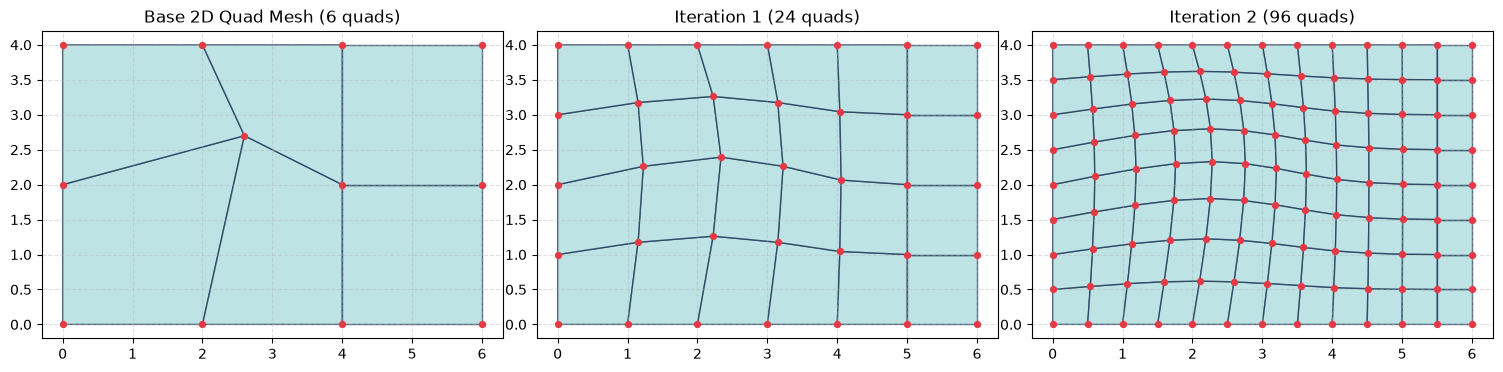

In [21]:
from collections import defaultdict
import matplotlib.pyplot as plt
import numpy as np


def catmull_clark_2d(vertices, faces, pin_corners=True):
  """Performs one iteration of Catmull-Clark subdivision on a 2D quad mesh.

  Args:
      vertices (list/array): 2D coordinates [[x, y], ...]
      faces (list of list): Quad vertex indices [[v0, v1, v2, v3], ...]
      pin_corners (bool): If True, keeps sharp corners fixed in place.

  Returns:
      tuple: (new_vertices, new_faces)
  """
  verts = [np.array(v, dtype=float) for v in vertices]

  # 1. Compute Face Points (centroid of each quad)
  face_points = []
  for face in faces:
    fp = np.mean([verts[idx] for idx in face], axis=0)
    face_points.append(fp)

  # Map edges and vertices to adjacent topology
  edge_to_faces = defaultdict(list)
  vert_to_faces = defaultdict(list)
  vert_to_edges = defaultdict(set)

  for f_idx, face in enumerate(faces):
    num_v = len(face)
    for i in range(num_v):
      v1 = face[i]
      v2 = face[(i + 1) % num_v]
      edge = tuple(sorted((v1, v2)))

      edge_to_faces[edge].append(f_idx)
      vert_to_faces[v1].append(f_idx)
      vert_to_edges[v1].add(edge)
      vert_to_edges[v2].add(edge)

  # 2. Compute Edge Points
  edge_points = {}
  for edge, adj_faces in edge_to_faces.items():
    e0, e1 = edge
    v1, v2 = verts[e0], verts[e1]

    if len(adj_faces) == 2:
      # Interior edge: average of endpoints and adjacent face points
      f0, f1 = adj_faces
      fp1, fp2 = face_points[f0], face_points[f1]
      edge_points[edge] = (v1 + v2 + fp1 + fp2) / 4.0
    else:
      # Boundary edge: midpoint of the two endpoints
      edge_points[edge] = (v1 + v2) / 2.0

  # 3. Update Original Vertex Positions
  new_orig_verts = []
  for v_idx, old_coord in enumerate(verts):
    adj_edges = vert_to_edges[v_idx]
    boundary_edges = [e for e in adj_edges if len(edge_to_faces[e]) == 1]

    if len(boundary_edges) >= 2:
      # Corner vertex (belongs to only 1 face) vs flat boundary edge vertex
      is_corner = len(vert_to_faces[v_idx]) == 1
      if pin_corners and is_corner:
        new_coord = old_coord.copy()
      else:
        b0, b1 = boundary_edges[0], boundary_edges[1]
        m1 = (verts[b0[0]] + verts[b0[1]]) / 2.0
        m2 = (verts[b1[0]] + verts[b1[1]]) / 2.0
        new_coord = (m1 + m2 + old_coord) / 3.0
    else:
      # Interior vertex rule: (F + 2R + (n - 3)P) / n
      adj_faces = vert_to_faces[v_idx]
      n = len(adj_faces)
      F = np.mean([face_points[f_idx] for f_idx in adj_faces], axis=0)
      edge_midpoints = [
          (verts[e[0]] + verts[e[1]]) / 2.0 for e in adj_edges
      ]
      R = np.mean(edge_midpoints, axis=0)
      new_coord = (F + 2.0 * R + (n - 3.0) * old_coord) / n

    new_orig_verts.append(new_coord)

  # 4. Assemble New Vertex List and Index Mappings
  final_vertices = list(new_orig_verts)

  face_point_offset = len(final_vertices)
  final_vertices.extend(face_points)

  edge_point_indices = {}
  for edge, ep in edge_points.items():
    edge_point_indices[edge] = len(final_vertices)
    final_vertices.append(ep)

  # 5. Reconnect Topology into New Quadrilateral Faces
  new_faces = []
  for f_idx, face in enumerate(faces):
    fp_idx = face_point_offset + f_idx
    num_v = len(face)
    for i in range(num_v):
      curr_v = face[i]
      prev_v = face[(i - 1) % num_v]
      next_v = face[(i + 1) % num_v]

      ep_prev = edge_point_indices[tuple(sorted((prev_v, curr_v)))]
      ep_next = edge_point_indices[tuple(sorted((curr_v, next_v)))]

      new_faces.append([curr_v, ep_next, fp_idx, ep_prev])

  return np.array(final_vertices), new_faces


def create_2d_quad_grid(rows, cols, width=4.0, height=4.0):
  """Generates a uniform 2D rectangular mesh divided into (rows x cols) quads."""
  xs = np.linspace(0.0, width, cols + 1)
  ys = np.linspace(0.0, height, rows + 1)

  vertices = []
  for r in range(rows + 1):
    for c in range(cols + 1):
      vertices.append([xs[c], ys[r]])

  faces = []
  stride = cols + 1
  for r in range(rows):
    for c in range(cols):
      v0 = r * stride + c
      v1 = v0 + 1
      v2 = v1 + stride
      v3 = v0 + stride
      faces.append([v0, v1, v2, v3])

  return np.array(vertices), faces


def plot_2d_mesh(ax, vertices, faces, title):
  """Plots a 2D quad mesh with shaded faces, wireframe edges, and vertex dots."""
  for face in faces:
    poly = vertices[face]
    ax.fill(
        poly[:, 0],
        poly[:, 1],
        facecolor="#a8dadc",
        edgecolor="#1d3557",
        linewidth=1.0,
        alpha=0.75,
    )

  ax.scatter(
      vertices[:, 0], vertices[:, 1], color="#e63946", s=18, zorder=3
  )
  ax.set_title(title)
  ax.set_aspect("equal")
  ax.grid(True, linestyle="--", alpha=0.4)


if __name__ == "__main__":
  # 1. Create a base 2D surface with 2x3 = 6 quad faces
  verts, faces = create_2d_quad_grid(rows=2, cols=3, width=6.0, height=4.0)

  # Slightly shift one interior vertex to show how the algorithm smooths irregular quads
  verts[5] = [2.6, 2.7]

  # 2. Subdivide twice (6 quads -> 24 quads -> 96 quads)
  v1, f1 = catmull_clark_2d(verts, faces, pin_corners=True)
  v2, f2 = catmull_clark_2d(v1, f1, pin_corners=True)

  print(f"Base Mesh   : {len(verts)} vertices, {len(faces)} quads")
  print(f"Iteration 1 : {len(v1)} vertices, {len(f1)} quads")
  print(f"Iteration 2 : {len(v2)} vertices, {len(f2)} quads")

  # 3. Visualize the progression side by side
  fig, axes = plt.subplots(1, 3, figsize=(15, 5))
  plot_2d_mesh(axes[0], verts, faces, f"Base 2D Quad Mesh ({len(faces)} quads)")
  plot_2d_mesh(axes[1], v1, f1, f"Iteration 1 ({len(f1)} quads)")
  plot_2d_mesh(axes[2], v2, f2, f"Iteration 2 ({len(f2)} quads)")
  plt.tight_layout()
  plt.show()


In [23]:
from collections import defaultdict
import tkinter as tk
import numpy as np


def catmull_clark_2d(vertices, faces, pin_corners=True):
  """Performs one iteration of Catmull-Clark subdivision on a 2D quad mesh."""
  verts = [np.array(v, dtype=float) for v in vertices]

  # 1. Compute Face Points
  face_points = [
      np.mean([verts[idx] for idx in face], axis=0) for face in faces
  ]

  # Map edges and vertices to adjacent topology
  edge_to_faces = defaultdict(list)
  vert_to_faces = defaultdict(list)
  vert_to_edges = defaultdict(set)

  for f_idx, face in enumerate(faces):
    num_v = len(face)
    for i in range(num_v):
      v1 = face[i]
      v2 = face[(i + 1) % num_v]
      edge = tuple(sorted((v1, v2)))
      edge_to_faces[edge].append(f_idx)
      vert_to_faces[v1].append(f_idx)
      vert_to_edges[v1].add(edge)
      vert_to_edges[v2].add(edge)

  # 2. Compute Edge Points
  edge_points = {}
  for edge, adj_faces in edge_to_faces.items():
    e0, e1 = edge
    v1, v2 = verts[e0], verts[e1]
    if len(adj_faces) == 2:
      f0, f1 = adj_faces
      fp1, fp2 = face_points[f0], face_points[f1]
      edge_points[edge] = (v1 + v2 + fp1 + fp2) / 4.0
    else:
      edge_points[edge] = (v1 + v2) / 2.0

  # 3. Update Original Vertex Positions
  new_orig_verts = []
  for v_idx, old_coord in enumerate(verts):
    adj_edges = vert_to_edges[v_idx]
    boundary_edges = [e for e in adj_edges if len(edge_to_faces[e]) == 1]

    if len(boundary_edges) >= 2:
      is_corner = len(vert_to_faces[v_idx]) == 1
      if pin_corners and is_corner:
        new_coord = old_coord.copy()
      else:
        b0, b1 = boundary_edges[0], boundary_edges[1]
        b0_u, b0_v = b0
        b1_u, b1_v = b1
        m1 = (verts[b0_u] + verts[b0_v]) / 2.0
        m2 = (verts[b1_u] + verts[b1_v]) / 2.0
        new_coord = (m1 + m2 + old_coord) / 3.0
    else:
      adj_faces = vert_to_faces[v_idx]
      n = len(adj_faces)
      F = np.mean([face_points[f_idx] for f_idx in adj_faces], axis=0)
      edge_midpoints = []
      for e in adj_edges:
        eu, ev = e
        edge_midpoints.append((verts[eu] + verts[ev]) / 2.0)
      R = np.mean(edge_midpoints, axis=0)
      new_coord = (F + 2.0 * R + (n - 3.0) * old_coord) / n

    new_orig_verts.append(new_coord)

  # 4. Assemble New Vertex List and Index Mappings
  final_vertices = list(new_orig_verts)
  face_point_offset = len(final_vertices)
  final_vertices.extend(face_points)

  edge_point_indices = {}
  for edge, ep in edge_points.items():
    edge_point_indices[edge] = len(final_vertices)
    final_vertices.append(ep)

  # 5. Reconnect Topology into New Quadrilateral Faces
  new_faces = []
  for f_idx, face in enumerate(faces):
    fp_idx = face_point_offset + f_idx
    num_v = len(face)
    for i in range(num_v):
      curr_v = face[i]
      prev_v = face[(i - 1) % num_v]
      next_v = face[(i + 1) % num_v]
      ep_prev = edge_point_indices[tuple(sorted((prev_v, curr_v)))]
      ep_next = edge_point_indices[tuple(sorted((curr_v, next_v)))]
      new_faces.append([curr_v, ep_next, fp_idx, ep_prev])

  return np.array(final_vertices), new_faces


class InteractiveQuadMeshApp:

  def __init__(self, root):
    self.root = root
    self.root.title("Interactive 2D Catmull-Clark Quad Mesh")

    self.canvas_w = 760
    self.canvas_h = 540
    self.selected_vertex = None
    self.hit_radius = 12

    # UI Controls Panel
    controls = tk.Frame(root, padx=10, pady=8, bg="#f1f5f9")
    controls.pack(side=tk.TOP, fill=tk.X)

    tk.Label(
        controls,
        text="Subdivision Level:",
        bg="#f1f5f9",
        font=("Arial", 10, "bold"),
    ).pack(side=tk.LEFT)
    self.subdiv_var = tk.IntVar(value=2)
    tk.Scale(
        controls,
        from_=0,
        to=4,
        orient=tk.HORIZONTAL,
        variable=self.subdiv_var,
        command=lambda _: self.redraw(),
        bg="#f1f5f9",
        highlightthickness=0,
    ).pack(side=tk.LEFT, padx=(4, 15))

    self.pin_var = tk.BooleanVar(value=True)
    tk.Checkbutton(
        controls,
        text="Pin Outer Corners",
        variable=self.pin_var,
        command=self.redraw,
        bg="#f1f5f9",
    ).pack(side=tk.LEFT, padx=8)

    self.cage_var = tk.BooleanVar(value=True)
    tk.Checkbutton(
        controls,
        text="Show Control Cage",
        variable=self.cage_var,
        command=self.redraw,
        bg="#f1f5f9",
    ).pack(side=tk.LEFT, padx=8)

    tk.Button(
        controls,
        text="Reset Grid",
        command=self.reset_mesh,
        bg="#e2e8f0",
        padx=10,
    ).pack(side=tk.RIGHT)

    # Status Bar
    self.status_var = tk.StringVar()
    tk.Label(
        root,
        textvariable=self.status_var,
        anchor="w",
        padx=10,
        pady=4,
        bg="#e2e8f0",
        font=("Consolas", 9),
    ).pack(side=tk.BOTTOM, fill=tk.X)

    # Drawing Canvas
    self.canvas = tk.Canvas(
        root, width=self.canvas_w, height=self.canvas_h, bg="#ffffff"
    )
    self.canvas.pack(fill=tk.BOTH, expand=True)

    # Mouse Events for Interactive Dragging
    self.canvas.bind("<ButtonPress-1>", self.on_mouse_down)
    self.canvas.bind("<B1-Motion>", self.on_mouse_drag)
    self.canvas.bind("<ButtonRelease-1>", self.on_mouse_up)

    self.reset_mesh()

  def reset_mesh(self):
    """Creates a 2x3 base control grid centered on the canvas."""
    rows, cols = 2, 3
    xs = np.linspace(140, self.canvas_w - 140, cols + 1)
    ys = np.linspace(110, self.canvas_h - 110, rows + 1)

    verts = []
    for r in range(rows + 1):
      for c in range(cols + 1):
        verts.append([xs[c], ys[r]])
    self.base_verts = np.array(verts, dtype=float)

    # Slightly offset one interior vertex so initial smoothing is visible
    self.base_verts[5] += np.array([-35.0, -45.0])

    self.base_faces = []
    stride = cols + 1
    for r in range(rows):
      for c in range(cols):
        v0 = r * stride + c
        v1 = v0 + 1
        v2 = v1 + stride
        v3 = v0 + stride
        self.base_faces.append([v0, v1, v2, v3])

    self.redraw()

  def on_mouse_down(self, event):
    """Finds the closest control vertex within click radius."""
    click_pt = np.array([event.x, event.y], dtype=float)
    dists = np.linalg.norm(self.base_verts - click_pt, axis=1)
    nearest_idx = int(np.argmin(dists))
    if dists[nearest_idx] <= self.hit_radius:
      self.selected_vertex = nearest_idx

  def on_mouse_drag(self, event):
    """Moves the dragged control vertex and updates the mesh live."""
    if self.selected_vertex is not None:
      x = np.clip(event.x, 20, self.canvas_w - 20)
      y = np.clip(event.y, 20, self.canvas_h - 20)
      self.base_verts[self.selected_vertex] = [x, y]
      self.redraw()

  def on_mouse_up(self, _event):
    self.selected_vertex = None

  def redraw(self):
    self.canvas.delete("all")
    levels = self.subdiv_var.get()
    pin = self.pin_var.get()

    v, f = self.base_verts.copy(), list(self.base_faces)
    for _ in range(levels):
      v, f = catmull_clark_2d(v, f, pin_corners=pin)

    # Draw subdivided quad faces
    wire_color = "#1d3557" if levels <= 2 else "#457b9d"
    for face in f:
      pts = v[face].flatten().tolist()
      self.canvas.create_polygon(
          pts, fill="#a8dadc", outline=wire_color, width=1
      )

    # Draw dashed control cage and draggable handles
    if self.cage_var.get():
      for face in self.base_faces:
        pts = self.base_verts[face].flatten().tolist()
        self.canvas.create_polygon(
            pts, fill="", outline="#e63946", width=1.5, dash=(5, 3)
        )

      for idx, (vx, vy) in enumerate(self.base_verts):
        r = 6
        fill_col = "#ffb703" if idx == self.selected_vertex else "#e63946"
        self.canvas.create_oval(
            vx - r,
            vy - r,
            vx + r,
            vy + r,
            fill=fill_col,
            outline="#ffffff",
            width=1.5,
        )

    self.status_var.set(
        f"Drag red control vertices to deform mesh | Subdivision Level: {levels}"
        f" | Vertices: {len(v)} | Quads: {len(f)}"
    )


if __name__ == "__main__":
  root = tk.Tk()
  app = InteractiveQuadMeshApp(root)
  root.mainloop()


In [24]:
from collections import defaultdict
import tkinter as tk
import numpy as np


def catmull_clark_2d(vertices, faces, pin_corners=True):
  """Performs one iteration of Catmull-Clark subdivision on a 2D quad or tri mesh."""
  verts = [np.array(v, dtype=float) for v in vertices]

  # 1. Compute Face Points (centroid of each triangle or quad)
  face_points = [
      np.mean([verts[idx] for idx in face], axis=0) for face in faces
  ]

  # Map edges and vertices to adjacent topology
  edge_to_faces = defaultdict(list)
  vert_to_faces = defaultdict(list)
  vert_to_edges = defaultdict(set)

  for f_idx, face in enumerate(faces):
    num_v = len(face)
    for i in range(num_v):
      v1 = face[i]
      v2 = face[(i + 1) % num_v]
      edge = tuple(sorted((v1, v2)))
      edge_to_faces[edge].append(f_idx)
      vert_to_faces[v1].append(f_idx)
      vert_to_edges[v1].add(edge)
      vert_to_edges[v2].add(edge)

  # 2. Compute Edge Points
  edge_points = {}
  for edge, adj_faces in edge_to_faces.items():
    e0, e1 = edge
    v1, v2 = verts[e0], verts[e1]
    if len(adj_faces) == 2:
      f0, f1 = adj_faces
      fp1, fp2 = face_points[f0], face_points[f1]
      edge_points[edge] = (v1 + v2 + fp1 + fp2) / 4.0
    else:
      edge_points[edge] = (v1 + v2) / 2.0

  # 3. Update Original Vertex Positions
  new_orig_verts = []
  for v_idx, old_coord in enumerate(verts):
    adj_edges = vert_to_edges[v_idx]
    boundary_edges = [e for e in adj_edges if len(edge_to_faces[e]) == 1]

    if len(boundary_edges) >= 2:
      # Corner vertex check: only 2 edges meet at the outer corners of the rectangle
      is_corner = len(adj_edges) == 2
      if pin_corners and is_corner:
        new_coord = old_coord.copy()
      else:
        b0, b1 = boundary_edges[0], boundary_edges[1]
        b0_u, b0_v = b0
        b1_u, b1_v = b1
        m1 = (verts[b0_u] + verts[b0_v]) / 2.0
        m2 = (verts[b1_u] + verts[b1_v]) / 2.0
        new_coord = (m1 + m2 + old_coord) / 3.0
    else:
      adj_faces = vert_to_faces[v_idx]
      n = len(adj_faces)
      F = np.mean([face_points[f_idx] for f_idx in adj_faces], axis=0)
      edge_midpoints = []
      for e in adj_edges:
        eu, ev = e
        edge_midpoints.append((verts[eu] + verts[ev]) / 2.0)
      R = np.mean(edge_midpoints, axis=0)
      new_coord = (F + 2.0 * R + (n - 3.0) * old_coord) / n

    new_orig_verts.append(new_coord)

  # 4. Assemble New Vertex List and Index Mappings
  final_vertices = list(new_orig_verts)
  face_point_offset = len(final_vertices)
  final_vertices.extend(face_points)

  edge_point_indices = {}
  for edge, ep in edge_points.items():
    edge_point_indices[edge] = len(final_vertices)
    final_vertices.append(ep)

  # 5. Reconnect Topology into New Quadrilateral Faces
  new_faces = []
  for f_idx, face in enumerate(faces):
    fp_idx = face_point_offset + f_idx
    num_v = len(face)
    for i in range(num_v):
      curr_v = face[i]
      prev_v = face[(i - 1) % num_v]
      next_v = face[(i + 1) % num_v]
      ep_prev = edge_point_indices[tuple(sorted((prev_v, curr_v)))]
      ep_next = edge_point_indices[tuple(sorted((curr_v, next_v)))]
      new_faces.append([curr_v, ep_next, fp_idx, ep_prev])

  return np.array(final_vertices), new_faces


class InteractiveMeshApp:

  def __init__(self, root):
    self.root = root
    self.root.title("Interactive 2D Catmull-Clark: Quad & Triangle Mesh")

    self.canvas_w = 820
    self.canvas_h = 560
    self.selected_vertex = None
    self.hit_radius = 12
    self.current_length = 520.0

    # Top Controls Bar (Row 1)
    top_bar = tk.Frame(root, padx=10, pady=6, bg="#f1f5f9")
    top_bar.pack(side=tk.TOP, fill=tk.X)

    tk.Label(
        top_bar,
        text="Mesh Type:",
        bg="#f1f5f9",
        font=("Arial", 10, "bold"),
    ).pack(side=tk.LEFT)

    self.mesh_type_var = tk.StringVar(value="tri")
    tk.Radiobutton(
        top_bar,
        text="Quad Mesh",
        variable=self.mesh_type_var,
        value="quad",
        command=self.rebuild_topology,
        bg="#f1f5f9",
    ).pack(side=tk.LEFT, padx=(4, 6))
    tk.Radiobutton(
        top_bar,
        text="Tri Mesh",
        variable=self.mesh_type_var,
        value="tri",
        command=self.rebuild_topology,
        bg="#f1f5f9",
    ).pack(side=tk.LEFT, padx=(0, 16))

    tk.Label(
        top_bar,
        text="Subdivision:",
        bg="#f1f5f9",
        font=("Arial", 10, "bold"),
    ).pack(side=tk.LEFT)
    self.subdiv_var = tk.IntVar(value=2)
    tk.Scale(
        top_bar,
        from_=0,
        to=4,
        orient=tk.HORIZONTAL,
        variable=self.subdiv_var,
        command=lambda _: self.redraw(),
        bg="#f1f5f9",
        highlightthickness=0,
        length=120,
    ).pack(side=tk.LEFT, padx=(4, 16))

    tk.Label(
        top_bar,
        text="Mesh Length:",
        bg="#f1f5f9",
        font=("Arial", 10, "bold"),
    ).pack(side=tk.LEFT)
    self.length_var = tk.DoubleVar(value=self.current_length)
    tk.Scale(
        top_bar,
        from_=200,
        to=720,
        orient=tk.HORIZONTAL,
        variable=self.length_var,
        command=self.on_length_change,
        bg="#f1f5f9",
        highlightthickness=0,
        length=140,
    ).pack(side=tk.LEFT, padx=(4, 10))

    # Second Controls Bar (Row 2)
    sub_bar = tk.Frame(root, padx=10, pady=4, bg="#e2e8f0")
    sub_bar.pack(side=tk.TOP, fill=tk.X)

    self.pin_var = tk.BooleanVar(value=True)
    tk.Checkbutton(
        sub_bar,
        text="Pin Outer Corners",
        variable=self.pin_var,
        command=self.redraw,
        bg="#e2e8f0",
    ).pack(side=tk.LEFT, padx=6)

    self.cage_var = tk.BooleanVar(value=True)
    tk.Checkbutton(
        sub_bar,
        text="Show Control Cage",
        variable=self.cage_var,
        command=self.redraw,
        bg="#e2e8f0",
    ).pack(side=tk.LEFT, padx=10)

    tk.Button(
        sub_bar,
        text="Reset Mesh",
        command=self.reset_mesh,
        bg="#cbd5e1",
        padx=10,
    ).pack(side=tk.RIGHT)

    # Status Bar
    self.status_var = tk.StringVar()
    tk.Label(
        root,
        textvariable=self.status_var,
        anchor="w",
        padx=10,
        pady=5,
        bg="#e2e8f0",
        font=("Consolas", 9),
    ).pack(side=tk.BOTTOM, fill=tk.X)

    # Drawing Canvas
    self.canvas = tk.Canvas(
        root, width=self.canvas_w, height=self.canvas_h, bg="#ffffff"
    )
    self.canvas.pack(fill=tk.BOTH, expand=True)

    # Mouse Events
    self.canvas.bind("<ButtonPress-1>", self.on_mouse_down)
    self.canvas.bind("<B1-Motion>", self.on_mouse_drag)
    self.canvas.bind("<ButtonRelease-1>", self.on_mouse_up)

    self.reset_mesh()

  def reset_mesh(self):
    """Creates a centered 2x3 base control grid with the current mesh length."""
    self.rows, self.cols = 2, 3
    self.current_length = self.length_var.get()
    center_x = self.canvas_w / 2.0
    half_len = self.current_length / 2.0

    xs = np.linspace(center_x - half_len, center_x + half_len, self.cols + 1)
    ys = np.linspace(120, self.canvas_h - 120, self.rows + 1)

    verts = []
    for r in range(self.rows + 1):
      for c in range(self.cols + 1):
        verts.append([xs[c], ys[r]])
    self.base_verts = np.array(verts, dtype=float)

    # Offset one interior vertex so initial smoothing is clearly visible
    self.base_verts[5] += np.array([-30.0, -40.0])

    self.rebuild_topology()

  def rebuild_topology(self):
    """Builds either 6 quad faces or 12 triangular faces over the 12 control vertices."""
    self.base_faces = []
    stride = self.cols + 1
    mode = self.mesh_type_var.get()

    for r in range(self.rows):
      for c in range(self.cols):
        v0 = r * stride + c
        v1 = v0 + 1
        v2 = v1 + stride
        v3 = v0 + stride

        if mode == "quad":
          self.base_faces.append([v0, v1, v2, v3])
        else:
          # Split each grid cell diagonally into 2 triangles
          self.base_faces.append([v0, v1, v2])
          self.base_faces.append([v0, v2, v3])

    self.redraw()

  def on_length_change(self, val_str):
    """Scales horizontal X coordinates around the canvas center when length changes."""
    new_length = float(val_str)
    if self.current_length > 0:
      scale_x = new_length / self.current_length
      center_x = self.canvas_w / 2.0
      self.base_verts[:, 0] = (
          center_x + (self.base_verts[:, 0] - center_x) * scale_x
      )
      self.current_length = new_length
      self.redraw()

  def on_mouse_down(self, event):
    click_pt = np.array([event.x, event.y], dtype=float)
    dists = np.linalg.norm(self.base_verts - click_pt, axis=1)
    nearest_idx = int(np.argmin(dists))
    if dists[nearest_idx] <= self.hit_radius:
      self.selected_vertex = nearest_idx

  def on_mouse_drag(self, event):
    if self.selected_vertex is not None:
      x = np.clip(event.x, 20, self.canvas_w - 20)
      y = np.clip(event.y, 20, self.canvas_h - 20)
      self.base_verts[self.selected_vertex] = [x, y]
      self.redraw()

  def on_mouse_up(self, _event):
    self.selected_vertex = None

  def redraw(self):
    self.canvas.delete("all")
    levels = self.subdiv_var.get()
    pin = self.pin_var.get()
    mode = self.mesh_type_var.get()

    v, f = self.base_verts.copy(), list(self.base_faces)
    for _ in range(levels):
      v, f = catmull_clark_2d(v, f, pin_corners=pin)

    # Distinct fill color for Quad vs Tri base topology
    fill_color = "#a8dadc" if mode == "quad" else "#bde0fe"
    wire_color = "#1d3557" if levels <= 2 else "#457b9d"

    for face in f:
      pts = v[face].flatten().tolist()
      self.canvas.create_polygon(
          pts, fill=fill_color, outline=wire_color, width=1
      )

    # Draw dashed control cage and draggable handles
    if self.cage_var.get():
      for face in self.base_faces:
        pts = self.base_verts[face].flatten().tolist()
        self.canvas.create_polygon(
            pts, fill="", outline="#e63946", width=1.5, dash=(5, 3)
        )

      for idx, (vx, vy) in enumerate(self.base_verts):
        r = 6
        fill_col = "#ffb703" if idx == self.selected_vertex else "#e63946"
        self.canvas.create_oval(
            vx - r,
            vy - r,
            vx + r,
            vy + r,
            fill=fill_col,
            outline="#ffffff",
            width=1.5,
        )

    face_label = "Quads" if (levels > 0 or mode == "quad") else "Triangles"
    self.status_var.set(
        f"Mode: {mode.upper()} | Length: {int(self.current_length)} px | "
        f"Subdiv Level: {levels} | Vertices: {len(v)} | {face_label}: {len(f)}"
    )


if __name__ == "__main__":
  root = tk.Tk()
  app = InteractiveMeshApp(root)
  root.mainloop()

In [35]:
from collections import defaultdict
import tkinter as tk
from tkinter import filedialog, messagebox
import numpy as np


def catmull_clark_creased(vertices, faces, edge_weights=None, pin_corners=False):
  """
    Performs one iteration of Catmull-Clark subdivision with semi-sharp edge creases.
    edge_weights: dict mapping sorted tuple (v1, v2) -> float crease sharpness (>= 0).
    Returns: (new_vertices, new_faces, next_edge_weights)
    """
  verts = [np.array(v, dtype=float) for v in vertices]
  if edge_weights is None:
    edge_weights = {}

  # 1. Compute Face Points (centroid of each face)
  face_points = [
      np.mean([verts[idx] for idx in face], axis=0) for face in faces
  ]

  # Map edges and vertices to adjacent topology
  edge_to_faces = defaultdict(list)
  vert_to_faces = defaultdict(list)
  vert_to_edges = defaultdict(set)

  for f_idx, face in enumerate(faces):
    num_v = len(face)
    for i in range(num_v):
      v1 = face[i]
      v2 = face[(i + 1) % num_v]
      edge = tuple(sorted((v1, v2)))
      edge_to_faces[edge].append(f_idx)
      vert_to_faces[v1].append(f_idx)
      vert_to_edges[v1].add(edge)
      vert_to_edges[v2].add(edge)

  # 2. Compute Edge Points (blending smooth rule and sharp crease midpoint)
  edge_points = {}
  for edge, adj_faces in edge_to_faces.items():
    e0, e1 = edge
    v1, v2 = verts[e0], verts[e1]
    midpoint = (v1 + v2) / 2.0
    w = edge_weights.get(edge, 0.0)

    if len(adj_faces) == 2:
      f0, f1 = adj_faces
      smooth_ep = (v1 + v2 + face_points[f0] + face_points[f1]) / 4.0
      if w >= 1.0:
        edge_points[edge] = midpoint
      elif w > 0.0:
        edge_points[edge] = (1.0 - w) * smooth_ep + w * midpoint
      else:
        edge_points[edge] = smooth_ep
    else:
      edge_points[edge] = midpoint

  # 3. Update Original Vertex Positions (DeRose et al. semi-sharp crease rules)
  new_orig_verts = []
  for v_idx, old_coord in enumerate(verts):
    adj_edges = vert_to_edges[v_idx]
    boundary_edges = [e for e in adj_edges if len(edge_to_faces[e]) == 1]
    sharp_edges = [e for e in adj_edges if edge_weights.get(e, 0.0) > 0.0]

    # Standard smooth Catmull-Clark target
    if len(boundary_edges) >= 2:
      if pin_corners and len(adj_edges) == 2:
        smooth_v = old_coord.copy()
      else:
        b0, b1 = boundary_edges[0], boundary_edges[1]
        m1 = (verts[b0[0]] + verts[b0[1]]) / 2.0
        m2 = (verts[b1[0]] + verts[b1[1]]) / 2.0
        smooth_v = (m1 + m2 + old_coord) / 3.0
    else:
      adj_faces = vert_to_faces[v_idx]
      n = len(adj_faces)
      F = np.mean([face_points[f_idx] for f_idx in adj_faces], axis=0)
      R = np.mean(
          [(verts[e[0]] + verts[e[1]]) / 2.0 for e in adj_edges], axis=0
      )
      smooth_v = (F + 2.0 * R + (n - 3.0) * old_coord) / n

    # Apply semi-sharp crease rules based on number of incident sharp edges
    if len(sharp_edges) >= 3:
      # Corner rule: vertex stays fixed while incident creases remain sharp
      avg_w = np.mean([min(edge_weights[e], 1.0) for e in sharp_edges])
      new_coord = (1.0 - avg_w) * smooth_v + avg_w * old_coord
    elif len(sharp_edges) == 2:
      # Crease curve rule: cubic B-spline curve rule (1/8, 6/8, 1/8)
      e0, e1 = sharp_edges[0], sharp_edges[1]
      other0 = e0[1] if e0[0] == v_idx else e0[0]
      other1 = e1[1] if e1[0] == v_idx else e1[0]
      crease_v = (verts[other0] + 6.0 * old_coord + verts[other1]) / 8.0
      avg_w = min(
          (edge_weights[e0] + edge_weights[e1]) / 2.0, 1.0
      )
      new_coord = (1.0 - avg_w) * smooth_v + avg_w * crease_v
    else:
      new_coord = smooth_v

    new_orig_verts.append(new_coord)

  # 4. Assemble New Vertex List and Index Mappings
  final_vertices = list(new_orig_verts)
  face_point_offset = len(final_vertices)
  final_vertices.extend(face_points)

  edge_point_indices = {}
  for edge, ep in edge_points.items():
    edge_point_indices[edge] = len(final_vertices)
    final_vertices.append(ep)

  # 5. Reconnect Topology into Quads & Propagate Decayed Edge Crease Weights
  new_faces = []
  next_edge_weights = {}

  for f_idx, face in enumerate(faces):
    fp_idx = face_point_offset + f_idx
    num_v = len(face)
    for i in range(num_v):
      curr_v = face[i]
      prev_v = face[(i - 1) % num_v]
      next_v = face[(i + 1) % num_v]

      edge_prev = tuple(sorted((prev_v, curr_v)))
      edge_next = tuple(sorted((curr_v, next_v)))

      ep_prev = edge_point_indices[edge_prev]
      ep_next = edge_point_indices[edge_next]

      new_faces.append([curr_v, ep_next, fp_idx, ep_prev])

      # Sub-edges inherit parent crease weight minus 1.0
      w_next = edge_weights.get(edge_next, 0.0) - 1.0
      if w_next > 0.0:
        next_edge_weights[tuple(sorted((curr_v, ep_next)))] = w_next

      w_prev = edge_weights.get(edge_prev, 0.0) - 1.0
      if w_prev > 0.0:
        next_edge_weights[tuple(sorted((curr_v, ep_prev)))] = w_prev

  return np.array(final_vertices), new_faces, next_edge_weights


class CatmullClark3DProApp:

  def __init__(self, root):
    self.root = root
    self.root.title("3D Catmull-Clark Studio: Rotation, Creases & OBJ/SVG Export")

    self.canvas_w = 880
    self.canvas_h = 600

    # 3D Camera Orbit Angles (radians) & Zoom
    self.yaw = 0.65
    self.pitch = 0.55
    self.zoom = 135.0
    self.last_mouse = None

    # Top Control Panel (Row 1: Geometry & Creases)
    bar1 = tk.Frame(root, padx=10, pady=6, bg="#f1f5f9")
    bar1.pack(side=tk.TOP, fill=tk.X)

    tk.Label(
        bar1, text="Shape:", bg="#f1f5f9", font=("Arial", 10, "bold")
    ).pack(side=tk.LEFT)
    self.shape_var = tk.StringVar(value="3d_sheet")
    tk.Radiobutton(
        bar1,
        text="3D Wavy Quad Sheet",
        variable=self.shape_var,
        value="3d_sheet",
        command=self.build_base_mesh,
        bg="#f1f5f9",
    ).pack(side=tk.LEFT, padx=4)
    tk.Radiobutton(
        bar1,
        text="3D Cube",
        variable=self.shape_var,
        value="cube",
        command=self.build_base_mesh,
        bg="#f1f5f9",
    ).pack(side=tk.LEFT, padx=4)

    tk.Label(
        bar1, text="Subdiv:", bg="#f1f5f9", font=("Arial", 10, "bold")
    ).pack(side=tk.LEFT, padx=(12, 2))
    self.subdiv_var = tk.IntVar(value=2)
    tk.Scale(
        bar1,
        from_=0,
        to=4,
        orient=tk.HORIZONTAL,
        variable=self.subdiv_var,
        command=lambda _: self.update_mesh(),
        bg="#f1f5f9",
        highlightthickness=0,
        length=100,
    ).pack(side=tk.LEFT, padx=4)

    tk.Label(
        bar1,
        text="Crease Weight:",
        bg="#f1f5f9",
        font=("Arial", 10, "bold"),
    ).pack(side=tk.LEFT, padx=(12, 2))
    self.crease_var = tk.DoubleVar(value=1.5)
    tk.Scale(
        bar1,
        from_=0.0,
        to=3.0,
        resolution=0.25,
        orient=tk.HORIZONTAL,
        variable=self.crease_var,
        command=lambda _: self.update_mesh(),
        bg="#f1f5f9",
        highlightthickness=0,
        length=120,
    ).pack(side=tk.LEFT, padx=4)

    # Second Control Panel (Row 2: Display & File Exports)
    bar2 = tk.Frame(root, padx=10, pady=5, bg="#e2e8f0")
    bar2.pack(side=tk.TOP, fill=tk.X)

    self.cage_var = tk.BooleanVar(value=True)
    tk.Checkbutton(
        bar2,
        text="Show Control Cage",
        variable=self.cage_var,
        command=self.render_3d,
        bg="#e2e8f0",
    ).pack(side=tk.LEFT, padx=4)

    tk.Button(
        bar2,
        text="Reset View",
        command=self.reset_camera,
        bg="#cbd5e1",
        padx=8,
    ).pack(side=tk.LEFT, padx=8)

    tk.Button(
        bar2,
        text="Export .SVG",
        command=self.export_svg,
        bg="#bae6fd",
        font=("Arial", 9, "bold"),
        padx=10,
    ).pack(side=tk.RIGHT, padx=4)
    tk.Button(
        bar2,
        text="Export .OBJ",
        command=self.export_obj,
        bg="#bbf7d0",
        font=("Arial", 9, "bold"),
        padx=10,
    ).pack(side=tk.RIGHT, padx=4)

    # Status Bar
    self.status_var = tk.StringVar()
    tk.Label(
        root,
        textvariable=self.status_var,
        anchor="w",
        padx=10,
        pady=5,
        bg="#e2e8f0",
        font=("Consolas", 9),
    ).pack(side=tk.BOTTOM, fill=tk.X)

    # 3D Viewport Canvas
    self.canvas = tk.Canvas(
        root, width=self.canvas_w, height=self.canvas_h, bg="#0f172a"
    )
    self.canvas.pack(fill=tk.BOTH, expand=True)

    # Mouse Orbit & Zoom Bindings
    self.canvas.bind("<ButtonPress-1>", self.on_mouse_down)
    self.canvas.bind("<B1-Motion>", self.on_mouse_drag)
    self.canvas.bind("<MouseWheel>", self.on_mouse_wheel)
    self.canvas.bind("<Button-4>", lambda e: self.adjust_zoom(1.1))
    self.canvas.bind("<Button-5>", lambda e: self.adjust_zoom(0.9))

    self.build_base_mesh()

  def reset_camera(self):
    self.yaw = 0.65
    self.pitch = 0.55
    self.zoom = 135.0
    self.render_3d()

  def build_base_mesh(self):
    shape = self.shape_var.get()
    if shape == "cube":
      self.base_verts = np.array(
          [
              [-1.0, -1.0, -1.0],
              [1.0, -1.0, -1.0],
              [1.0, 1.0, -1.0],
              [-1.0, 1.0, -1.0],
              [-1.0, -1.0, 1.0],
              [1.0, -1.0, 1.0],
              [1.0, 1.0, 1.0],
              [-1.0, 1.0, 1.0],
          ],
          dtype=float,
      )
      self.base_faces = [
            [0, 3, 2, 1],
            [4, 5, 6, 7],
            [0, 1, 5, 4],
            [2, 3, 7, 6],
            [0, 4, 7, 3],
            [1, 2, 6, 5],
      ]
      # Apply crease weight to the top 4 edges of the cube
      self.creased_edges = [(4, 5), (5, 6), (6, 7), (7, 4)]
      # Apply crease weight to the top 4 edges of the cube
      self.creased_edges = [(4, 5), (5, 6), (6, 7), (7, 4)]
    else:
      # 3x3 grid of 16 vertices forming 9 quads with a raised center ridge
      rows, cols = 3, 3
      xs = np.linspace(-1.8, 1.8, cols + 1)
      ys = np.linspace(-1.8, 1.8, rows + 1)
      verts = []
      for r in range(rows + 1):
        for c in range(cols + 1):
          z = 0.85 if (r in (1, 2) and c in (1, 2)) else -0.2
          if r == 1 and c == 1:
            z = 1.15
          verts.append([xs[c], ys[r], z])
      self.base_verts = np.array(verts, dtype=float)

      self.base_faces = []
      stride = cols + 1
      for r in range(rows):
        for c in range(cols):
          v0 = r * stride + c
          v1 = v0 + 1
          v2 = v1 + stride
          v3 = v0 + stride
          self.base_faces.append([v0, v1, v2, v3])

      # Apply crease weight along the outer perimeter edges
      self.creased_edges = [
          (0, 1),
          (1, 2),
          (2, 3),
          (3, 7),
          (7, 11),
          (11, 15),
          (15, 14),
          (14, 13),
          (13, 12),
          (12, 8),
          (8, 4),
          (4, 0),
      ]

    self.update_mesh()


  def update_mesh(self):
    levels = self.subdiv_var.get()
    w = self.crease_var.get()
    edge_weights = {
        tuple(sorted(e)): w for e in self.creased_edges if w > 0.0
    }

    v = self.base_verts.copy()
    f = list(self.base_faces)

    for _ in range(levels):
      v, f, edge_weights = catmull_clark_creased(
          v, f, edge_weights=edge_weights, pin_corners=False
      )

    self.curr_verts = v
    self.curr_faces = f
    self.render_3d()

  def project_points(self, pts_3d):
    """Rotates 3D points by (yaw, pitch) and projects onto the 2D Tkinter canvas."""
    cy, sy = np.cos(self.yaw), np.sin(self.yaw)
    cp, sp = np.cos(self.pitch), np.sin(self.pitch)

    # Rotate around Z (yaw) then X (pitch)
    rot_z = np.array([[cy, -sy, 0.0], [sy, cy, 0.0], [0.0, 0.0, 1.0]])
    rot_x = np.array([[1.0, 0.0, 0.0], [0.0, cp, -sp], [0.0, sp, cp]])
    rotated = pts_3d @ rot_z.T @ rot_x.T

    # Perspective projection
    cam_dist = 6.0
    depths = cam_dist - rotated[:, 2]
    depths = np.maximum(depths, 0.5)
    perspective = (cam_dist / depths) * self.zoom

    proj_x = self.canvas_w / 2.0 + rotated[:, 0] * perspective
    proj_y = self.canvas_h / 2.0 - rotated[:, 1] * perspective
    return np.column_stack((proj_x, proj_y)), rotated

  def render_3d(self):
    self.canvas.delete("all")
    proj_2d, rot_3d = self.project_points(self.curr_verts)

    # Painter's algorithm: sort faces back-to-front by average Z depth
    face_depths = []
    for idx, face in enumerate(self.curr_faces):
      avg_z = np.mean(rot_3d[face, 2])
      face_depths.append((avg_z, idx))
    face_depths.sort(key=lambda item: item[0])

    light_dir = np.array([0.4, -0.5, 0.77])
    light_dir /= np.linalg.norm(light_dir)

    self.last_projected_polys = []

    for _, f_idx in face_depths:
      face = self.curr_faces[f_idx]
      poly_3d = rot_3d[face]

      # Compute face normal for directional shading
      v_a = poly_3d[1] - poly_3d[0]
      v_b = poly_3d[2] - poly_3d[0]
      normal = np.cross(v_a, v_b)
      norm_len = np.linalg.norm(normal)
      if norm_len > 1e-8:
        normal /= norm_len

      intensity = 0.35 + 0.65 * abs(float(np.dot(normal, light_dir)))
      r = int(np.clip(56 * intensity, 0, 255))
      g = int(np.clip(189 * intensity, 0, 255))
      b = int(np.clip(248 * intensity, 0, 255))
      hex_fill = f"#{r:02x}{g:02x}{b:02x}"

      pts = proj_2d[face].flatten().tolist()
      self.canvas.create_polygon(
          pts, fill=hex_fill, outline="#0f172a", width=0.8
      )
      self.last_projected_polys.append((proj_2d[face], hex_fill))

    # Optional Base Control Cage Overlay
    if self.cage_var.get():
      cage_2d, _ = self.project_points(self.base_verts)
      creased_set = {tuple(sorted(e)) for e in self.creased_edges}

      for face in self.base_faces:
        pts = cage_2d[face].flatten().tolist()
        self.canvas.create_polygon(
            pts, fill="", outline="#94a3b8", width=1.0, dash=(4, 3)
        )

      # Highlight creased edges in bright amber
      if self.crease_var.get() > 0.0:
        for e0, e1 in creased_set:
          x0, y0 = cage_2d[e0]
          x1, y1 = cage_2d[e1]
          self.canvas.create_line(
              x0, y0, x1, y1, fill="#f59e0b", width=2.5
          )

    self.status_var.set(
        f"Drag canvas to rotate 3D | Scroll to zoom | Subdiv:"
        f" {self.subdiv_var.get()} | Crease: {self.crease_var.get():.2f} |"
        f" Vertices: {len(self.curr_verts)} | Quads: {len(self.curr_faces)}"
    )

  def on_mouse_down(self, event):
    self.last_mouse = (event.x, event.y)

  def on_mouse_drag(self, event):
    if self.last_mouse is not None:
      dx = event.x - self.last_mouse[0]
      dy = event.y - self.last_mouse[1]
      self.yaw += dx * 0.01
      self.pitch = np.clip(
          self.pitch + dy * 0.01, -np.pi / 2 + 0.05, np.pi / 2 - 0.05
      )
      self.last_mouse = (event.x, event.y)
      self.render_3d()

  def on_mouse_wheel(self, event):
    factor = 1.1 if event.delta > 0 else 0.9
    self.adjust_zoom(factor)

  def adjust_zoom(self, factor):
    self.zoom = float(np.clip(self.zoom * factor, 40.0, 450.0))
    self.render_3d()

  def export_obj(self):
    filepath = filedialog.asksaveasfilename(
        defaultextension=".obj",
        filetypes=[("Wavefront OBJ", "*.obj")],
        initialfile="subdivided_mesh.obj",
    )
    if not filepath:
      return
    with open(filepath, "w") as f:
      f.write("# Exported from 3D Catmull-Clark Studio\n")
      for x, y, z in self.curr_verts:
        f.write(f"v {x:.6f} {y:.6f} {z:.6f}\n")
      for face in self.curr_faces:
        indices = " ".join(str(idx + 1) for idx in face)
        f.write(f"f {indices}\n")
    messagebox.showinfo("Export Complete", f"Saved 3D mesh to:\n{filepath}")

  def export_svg(self):
    filepath = filedialog.asksaveasfilename(
        defaultextension=".svg",
        filetypes=[("Scalable Vector Graphics", "*.svg")],
        initialfile="subdivided_view.svg",
    )
    if not filepath:
      return
    with open(filepath, "w") as f:
      f.write(
          f'<svg xmlns="http://w3.org" width="{self.canvas_w}"'
          f' height="{self.canvas_h}" viewBox="0 0 {self.canvas_w}'
          f' {self.canvas_h}">\n'
      )
      f.write('  <rect width="100%" height="100%" fill="#0f172a"/>\n')
      for poly_pts, fill_col in self.last_projected_polys:
        pts_str = " ".join(f"{x:.2f},{y:.2f}" for x, y in poly_pts)
        f.write(
            f'  <polygon points="{pts_str}" fill="{fill_col}"'
            ' stroke="#0f172a" stroke-width="0.6"/>\n'
        )
      f.write("</svg>\n")
    messagebox.showinfo("Export Complete", f"Saved 2D vector view to:\n{filepath}")


if __name__ == "__main__":
  root = tk.Tk()
  app = CatmullClark3DProApp(root)
  root.mainloop()
